In [13]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Ajouter le dossier racine du projet au chemin de recherche Python
racine_projet = Path.cwd().parent
sys.path.insert(0, str(racine_projet))

from api.api_client import fetch_dataset

df = fetch_dataset("meteo")

print(df.head())

         lat     lon  geo_id_insee        reference_time  \
0  48.844833  2.3385      75106001  2026-11-04T21:10:05Z   
1  48.844833  2.3385      75106001  2026-11-04T20:10:08Z   
2  48.844833  2.3385      75106001  2026-11-04T19:10:06Z   
3  48.844833  2.3385      75106001  2026-11-04T18:10:07Z   
4  48.844833  2.3385      75106001  2026-11-04T17:10:06Z   

            insert_time         validity_time  temperature_celsius  \
0  2026-11-04T21:02:10Z  2026-11-04T21:00:00Z                  8.7   
1  2026-11-04T20:02:10Z  2026-11-04T20:00:00Z                  8.7   
2  2026-11-04T19:02:10Z  2026-11-04T19:00:00Z                  8.8   
3  2026-11-04T18:02:14Z  2026-11-04T18:00:00Z                  9.0   
4  2026-11-04T17:02:09Z  2026-11-04T17:00:00Z                  9.1   

   temperature_point_rosee_celsius  temperature_max_celsius  \
0                              NaN                      8.7   
1                              NaN                      8.8   
2                            

In [14]:
# ============================================================
# 1. CHARGEMENT DU DATASET
# ============================================================

# Conversion des colonnes temporelles
colonnes_dates = [
    "reference_time",
    "insert_time",
    "validity_time"
]

for col in colonnes_dates:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], utc=True)

In [15]:
# ============================================================
# 2. INFORMATIONS GENERALES
# ============================================================

print("\n========== INFORMATIONS GENERALES ==========")

print("Dimensions du dataset :", df.shape)

print("\nTypes des variables :")
print(df.dtypes)

print("\nInformations générales :")
df.info()

print("\nAperçu du dataset :")
print(df.head())


========== INFORMATIONS GENERALES ==========
Dimensions du dataset : (707, 32)

Types des variables :
lat                                            float64
lon                                            float64
geo_id_insee                                     int64
reference_time                     datetime64[us, UTC]
insert_time                        datetime64[us, UTC]
validity_time                      datetime64[us, UTC]
temperature_celsius                            float64
temperature_point_rosee_celsius                float64
temperature_max_celsius                        float64
temperature_min_celsius                        float64
u                                              float64
ux                                             float64
un                                             float64
dd                                             float64
ff                                             float64
dxy                                            float64
fxy              

In [16]:
# ============================================================
# 3. STATISTIQUES DESCRIPTIVES
# ============================================================

print("\n========== STATISTIQUES DESCRIPTIVES ==========")

# Sélection des variables numériques
df_num = df.select_dtypes(include=np.number)

# Statistiques classiques
stats = df_num.describe().T

# Ajout de statistiques complémentaires
stats["median"] = df_num.median()
stats["variance"] = df_num.var()
stats["skewness"] = df_num.skew()
stats["kurtosis"] = df_num.kurt()

print(stats.round(3))

# Export des statistiques
stats.to_csv("statistiques_descriptives.csv")


========== STATISTIQUES DESCRIPTIVES ==========
                                 count          mean         std  \
lat                              707.0  4.884700e+01       0.021   
lon                              707.0  2.316000e+00       0.041   
geo_id_insee                     707.0  7.511118e+07    3763.743   
temperature_celsius              707.0  8.928000e+00       2.270   
temperature_point_rosee_celsius  236.0  4.740000e+00       2.467   
temperature_max_celsius          705.0  9.220000e+00       2.296   
temperature_min_celsius          705.0  8.681000e+00       2.211   
u                                236.0  7.661000e+01      12.737   
ux                               236.0  7.872900e+01      12.407   
un                               236.0  7.452100e+01      12.851   
dd                               352.0  5.858000e+01      55.994   
ff                               352.0  4.720000e+00       2.998   
dxy                              349.0  6.017200e+01      56.058   


========== VALEURS MANQUANTES ==========
                                 nb_valeurs_manquantes  pourcentage_manquant
n                                                  707                100.00
etat_sol                                           707                100.00
pmer                                               589                 83.31
t_10                                               589                 83.31
pres                                               589                 83.31
sss                                                589                 83.31
vv                                                 589                 83.31
t_100                                              589                 83.31
t_50                                               589                 83.31
t_20                                               589                 83.31
ray_glo01                                          471                 66.62
insolh                            

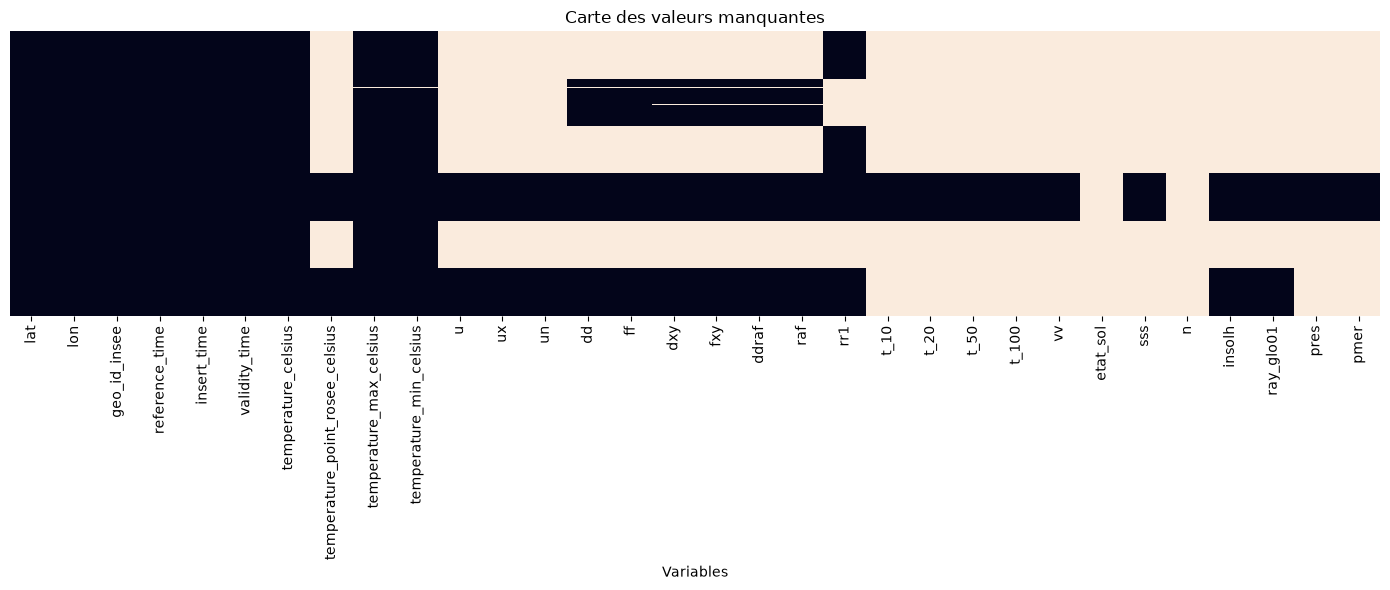

In [17]:
# ============================================================
# 4. ANALYSE DES VALEURS MANQUANTES
# ============================================================

print("\n========== VALEURS MANQUANTES ==========")

missing = pd.DataFrame({
    "nb_valeurs_manquantes": df.isnull().sum(),
    "pourcentage_manquant": (
        df.isnull().mean() * 100
    )
})

missing = missing.sort_values(
    by="pourcentage_manquant",
    ascending=False
)

print(missing.round(2))

# Visualisation des valeurs manquantes
plt.figure(figsize=(14, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Carte des valeurs manquantes")
plt.xlabel("Variables")
plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# 5. ANALYSE DES TEMPERATURES
# ============================================================

temperature_cols = [
    "temperature_celsius",
    "temperature_max_celsius",
    "temperature_min_celsius",
    "temperature_point_rosee_celsius"
]

temperature_cols = [
    col for col in temperature_cols
    if col in df.columns
]

print("\n========== STATISTIQUES DES TEMPERATURES ==========")

print(
    df[temperature_cols].describe().T.round(2)
)


========== STATISTIQUES DES TEMPERATURES ==========
                                 count  mean   std  min   25%  50%   75%   max
temperature_celsius              707.0  8.93  2.27  2.3  7.40  8.9   9.9  16.2
temperature_max_celsius          705.0  9.22  2.30  2.8  7.60  9.1  10.2  16.3
temperature_min_celsius          705.0  8.68  2.21  2.0  7.20  8.7   9.7  15.9
temperature_point_rosee_celsius  236.0  4.74  2.47 -0.1  2.68  5.4   6.5   9.4


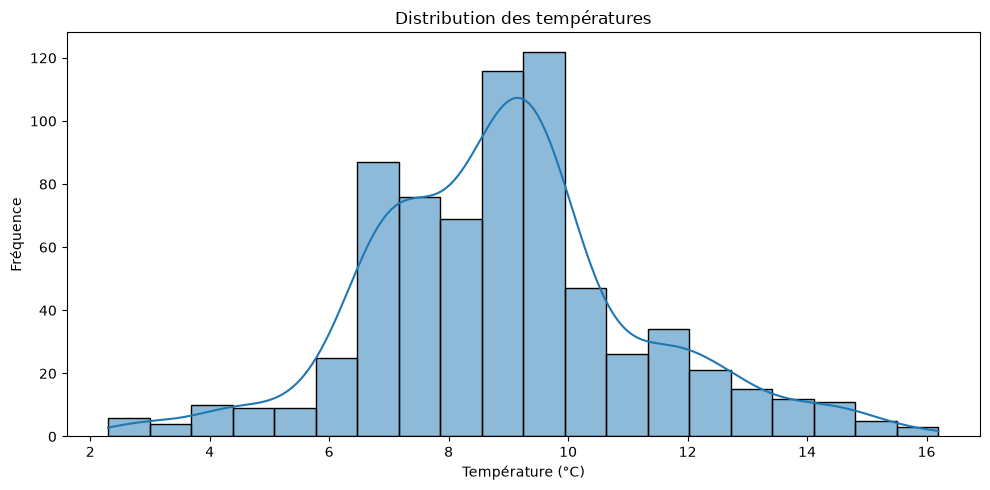

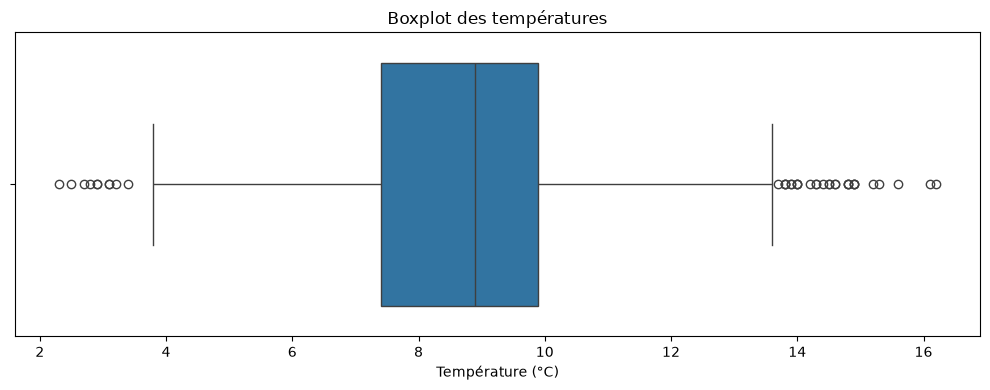

In [19]:
# ============================================================
# 6. DISTRIBUTION DES TEMPERATURES
# ============================================================

if "temperature_celsius" in df.columns:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        df["temperature_celsius"].dropna(),
        bins=20,
        kde=True
    )

    plt.title("Distribution des températures")
    plt.xlabel("Température (°C)")
    plt.ylabel("Fréquence")

    plt.tight_layout()
    plt.show()

    # Boxplot
    plt.figure(figsize=(10, 4))

    sns.boxplot(
        x=df["temperature_celsius"]
    )

    plt.title("Boxplot des températures")
    plt.xlabel("Température (°C)")

    plt.tight_layout()
    plt.show()

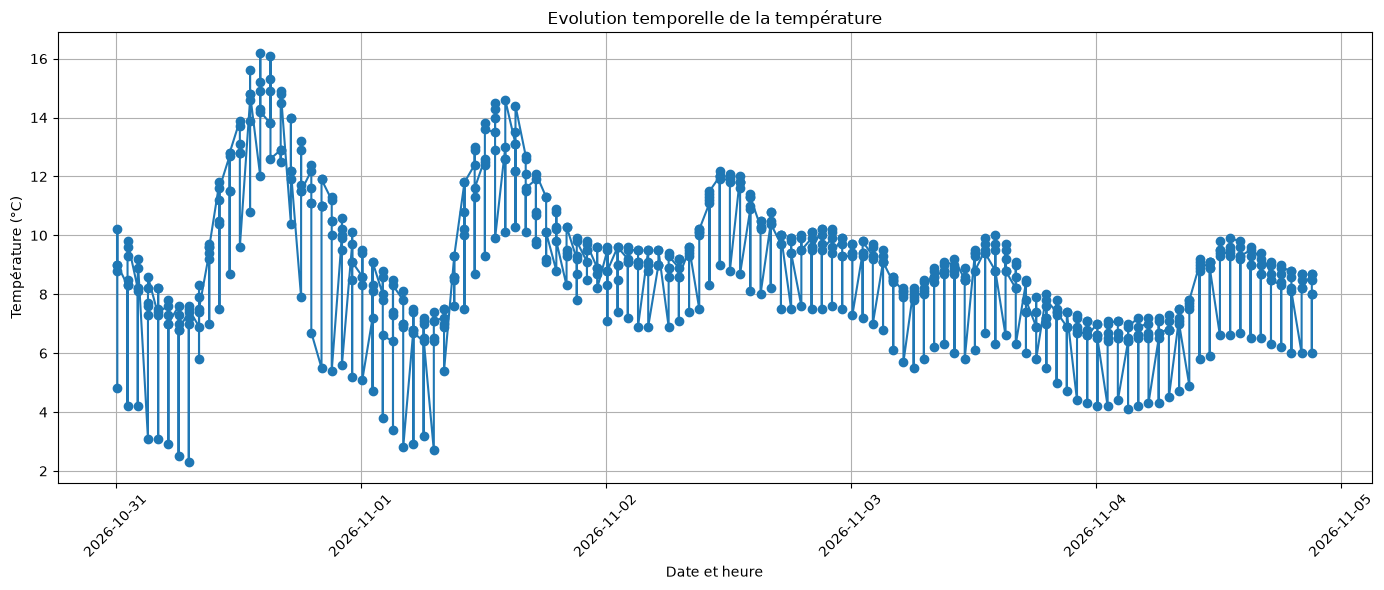

In [20]:
# ============================================================
# 7. EVOLUTION TEMPORELLE
# ============================================================

if (
    "reference_time" in df.columns
    and "temperature_celsius" in df.columns
):

    df = df.sort_values("reference_time")

    plt.figure(figsize=(14, 6))

    plt.plot(
        df["reference_time"],
        df["temperature_celsius"],
        marker="o",
        linestyle="-"
    )

    plt.title("Evolution temporelle de la température")
    plt.xlabel("Date et heure")
    plt.ylabel("Température (°C)")

    plt.xticks(rotation=45)
    plt.grid(True)

    plt.tight_layout()
    plt.show()

In [21]:
# ============================================================
# 8. DETECTION DES VALEURS ABERRANTES (IQR)
# ============================================================

print("\n========== DETECTION DES OUTLIERS ==========")

for col in df_num.columns:

    serie = df[col].dropna()

    if serie.empty:
        continue

    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)

    IQR = Q3 - Q1

    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    outliers = serie[
        (serie < borne_inf) |
        (serie > borne_sup)
    ]

    print(f"\nVariable : {col}")
    print("Borne inférieure :", round(borne_inf, 3))
    print("Borne supérieure :", round(borne_sup, 3))
    print("Nombre d'outliers :", len(outliers))


========== DETECTION DES OUTLIERS ==========

Variable : lat
Borne inférieure : 48.767
Borne supérieure : 48.913
Nombre d'outliers : 0

Variable : lon
Borne inférieure : 2.229
Borne supérieure : 2.404
Nombre d'outliers : 0

Variable : geo_id_insee
Borne inférieure : 75096502.0
Borne supérieure : 75124510.0
Nombre d'outliers : 0

Variable : temperature_celsius
Borne inférieure : 3.65
Borne supérieure : 13.65
Nombre d'outliers : 38

Variable : temperature_point_rosee_celsius
Borne inférieure : -3.062
Borne supérieure : 12.238
Nombre d'outliers : 0

Variable : temperature_max_celsius
Borne inférieure : 3.7
Borne supérieure : 14.1
Nombre d'outliers : 34

Variable : temperature_min_celsius
Borne inférieure : 3.45
Borne supérieure : 13.45
Nombre d'outliers : 34

Variable : u
Borne inférieure : 31.0
Borne supérieure : 121.0
Nombre d'outliers : 0

Variable : ux
Borne inférieure : 34.0
Borne supérieure : 122.0
Nombre d'outliers : 0

Variable : un
Borne inférieure : 26.0
Borne supérieure : 122.


========== MATRICE DE CORRELATION ==========
                                  lat   lon  geo_id_insee  \
lat                              1.00 -0.14         -0.38   
lon                             -0.14  1.00         -0.37   
geo_id_insee                    -0.38 -0.37          1.00   
temperature_celsius             -0.04  0.24          0.01   
temperature_point_rosee_celsius -0.03  0.03         -0.03   
temperature_max_celsius         -0.04  0.21          0.02   
temperature_min_celsius         -0.04  0.27         -0.02   
u                                0.15 -0.15          0.15   
ux                               0.18 -0.18          0.18   
un                               0.14 -0.14          0.14   
dd                               0.05 -0.06          0.02   
ff                               0.38  0.20         -0.86   
dxy                              0.06 -0.08          0.03   
fxy                              0.38  0.21         -0.86   
ddraf                            0.04 -

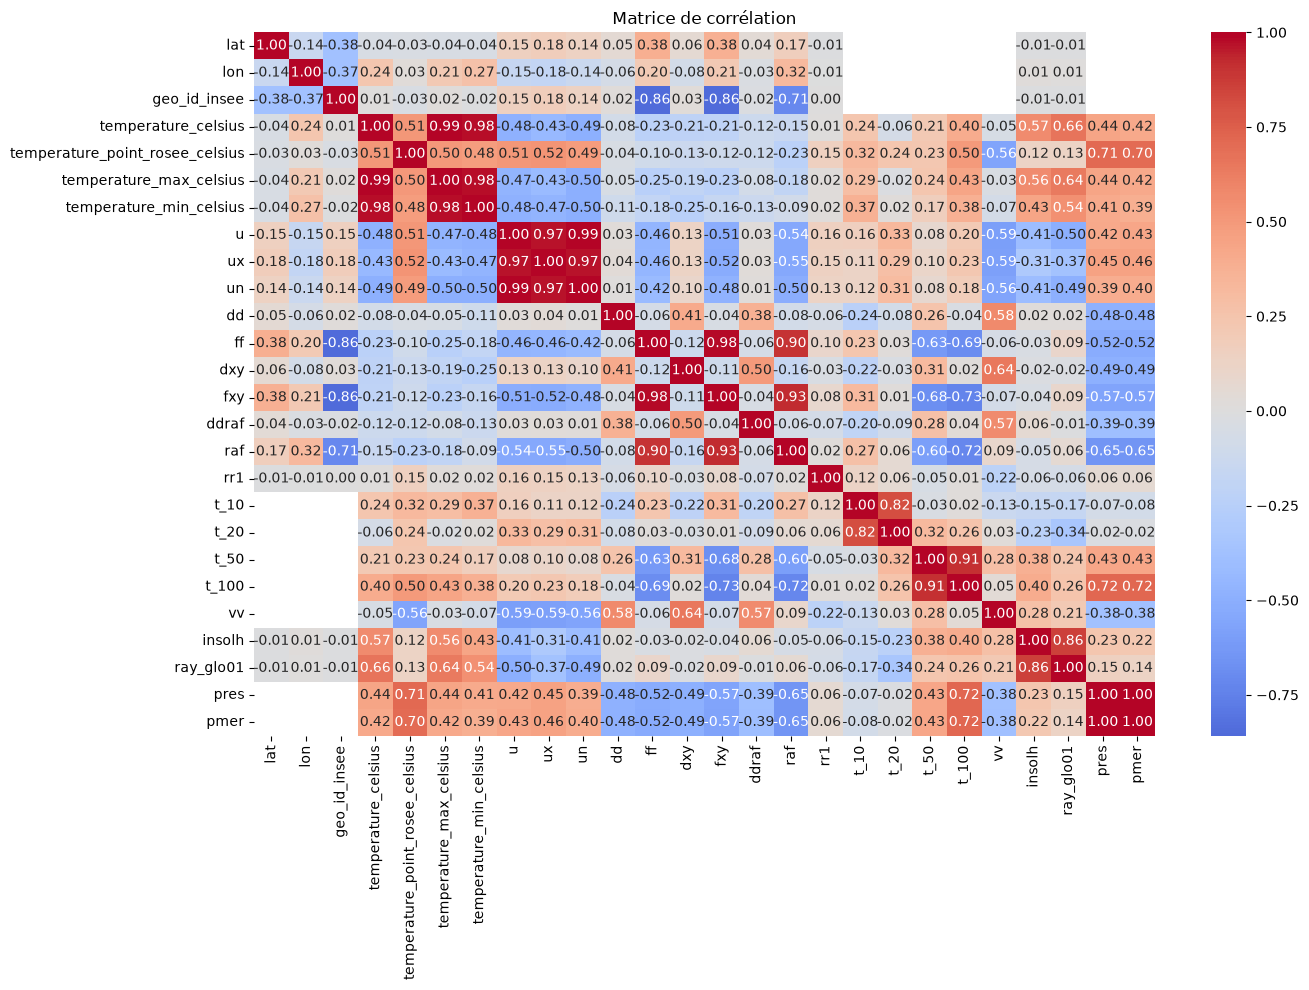

In [22]:
# ============================================================
# 9. MATRICE DE CORRELATION
# ============================================================

# On retire les variables numériques constantes
df_corr = df_num.loc[
    :, df_num.nunique(dropna=True) > 1
]

if not df_corr.empty:

    correlation = df_corr.corr()

    print("\n========== MATRICE DE CORRELATION ==========")

    print(correlation.round(2))

    plt.figure(figsize=(14, 10))

    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        center=0
    )

    plt.title("Matrice de corrélation")

    plt.tight_layout()
    plt.show()

In [23]:
# ============================================================
# 10. EXPORT DES RESULTATS
# ============================================================

missing.to_csv("valeurs_manquantes.csv")

print("\nAnalyse statistique terminée.")



Analyse statistique terminée.
